In [6]:
import numpy as np
import scipy.stats as stats
from scipy.stats import skew
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline


from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, TargetEncoder, FunctionTransformer, RobustScaler, MinMaxScaler

from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import GridSearchCV
import time

# EDA

## Overview

In [12]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/train.csv')
quantitative = [f for f in train.columns if train.dtypes[f] != 'object']
quantitative.remove('SalePrice')
quantitative.remove('Id')
qualitative = [f for f in train.columns if train.dtypes[f] == 'object']

In [13]:
train.head(5) #81 columns

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<Axes: >

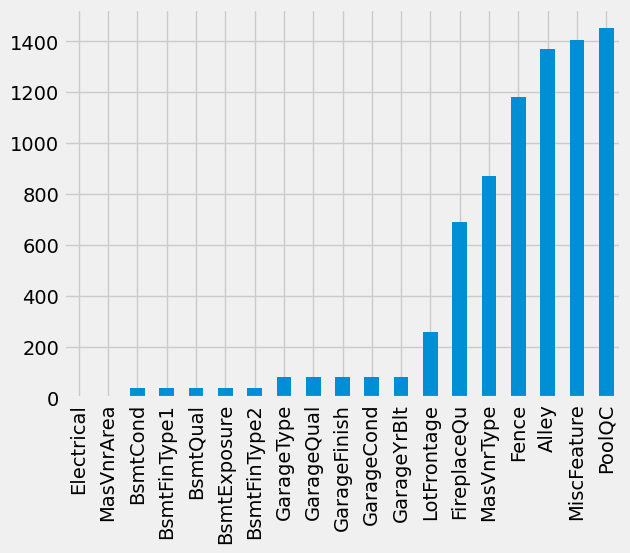

In [14]:
missing = train.isnull().sum()
missing = missing[missing > 0]
missing.sort_values(inplace=True)
missing.plot.bar()

19 attributes have missing values, 5 over 50% of all data. Most of times NA means lack of subject described by attribute, like missing pool, fence, no garage and basement.

<Axes: title={'center': 'Log Normal'}, xlabel='SalePrice'>

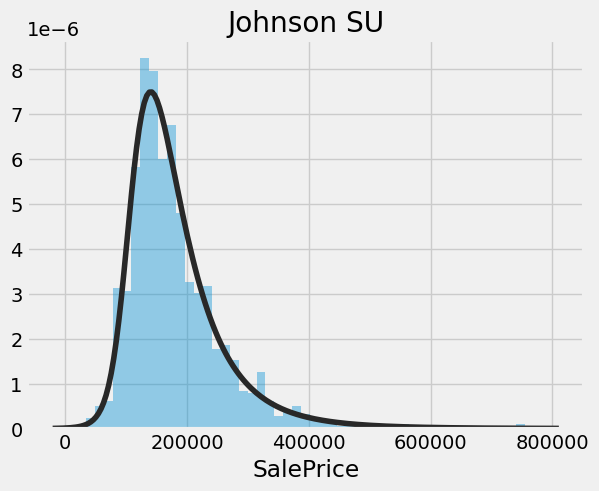

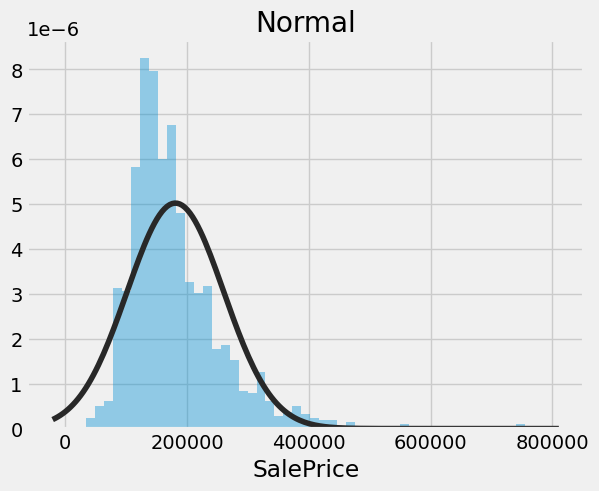

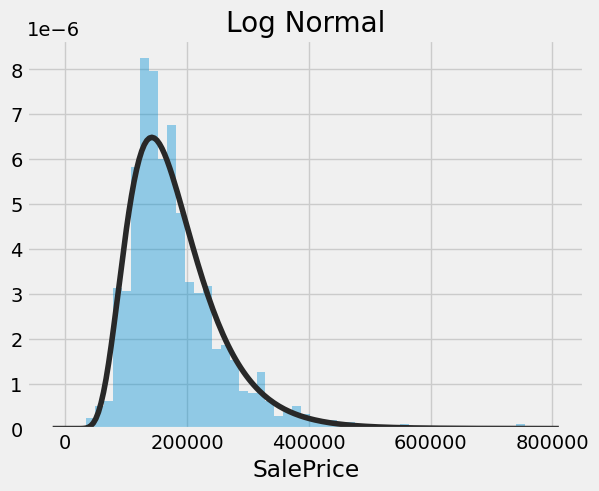

In [15]:
import scipy.stats as st
y = train['SalePrice']
plt.figure(1); plt.title('Johnson SU')
sns.distplot(y, kde=False, fit=st.johnsonsu)
plt.figure(2); plt.title('Normal')
sns.distplot(y, kde=False, fit=st.norm)
plt.figure(3); plt.title('Log Normal')
sns.distplot(y, kde=False, fit=st.lognorm)

It is apparent that SalePrice doesn't follow normal distribution, so before performing regression it has to be transformed. While log transformation does pretty good job, best fit is unbounded Johnson distribution.

In [16]:
test_normality = lambda x: stats.shapiro(x.fillna(0))[1] < 0.01
normal = pd.DataFrame(train[quantitative])
normal = normal.apply(test_normality)
print(not normal.any())

False


Also none of quantitative variables has normal distribution so these should be transformed as well.

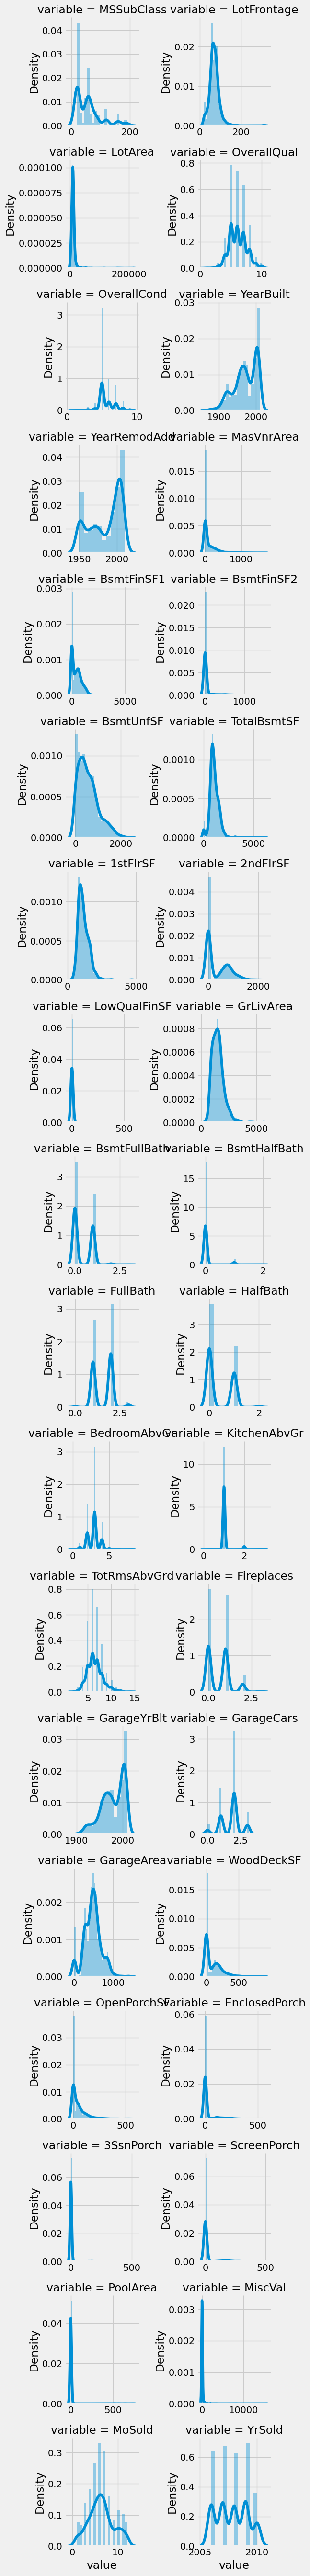

In [17]:
f = pd.melt(train, value_vars=quantitative)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False)
g = g.map(sns.distplot, "value")

Some independent variables look like good candidates for log transformation: TotalBsmtSF, KitchenAbvGr, LotFrontage, LotArea and others. While ganining on regression transformation will smooth out some irregularities which could be important like large amount of houses with 0 2ndFlrSF. Such irregularities are good candidates for feature construction.

Log-transformation - применение логарифма к данных для сглаживания выбросов и приведению к нормальному виду

1. Нужно заполнить пропущенные данные, причем некоторые пропуски означают просто отсутсвие объекта в доме (бассейн, чердак...)
2. Saleprice имеет ненормальное распределение(логарифмическое или скорее johonsonSU)
3. Некоторые численные признаки являются хорошими кандидатами для логарифмического преобразования. Однако некоторые нерегулярности могут послужить неплохими кандидатами для создания признаков

## Categorical data

With qualitative variables we can implement two methods. First one is to check distribution of SalePrice with respect to variable values and enumerate them. Second to create dummy variable for each possible category.



In [18]:
for c in qualitative:
    train[c] = train[c].astype('category')
    if train[c].isnull().any():
        train[c] = train[c].cat.add_categories(['MISSING'])
        train[c] = train[c].fillna('MISSING')

def boxplot(x, y, **kwargs):
    sns.boxplot(x=x, y=y)
    x=plt.xticks(rotation=90)
f = pd.melt(train, id_vars=['SalePrice'], value_vars=qualitative)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False, height = 5)
g = g.map(boxplot, "value", "SalePrice")

Some categories seem to more diverse with respect to SalePrice than others. Neighborhood has big impact on house prices. Most expensive seems to be Partial SaleCondition. Having pool on property seems to improve price substantially. There are also differences in variabilities between category values.

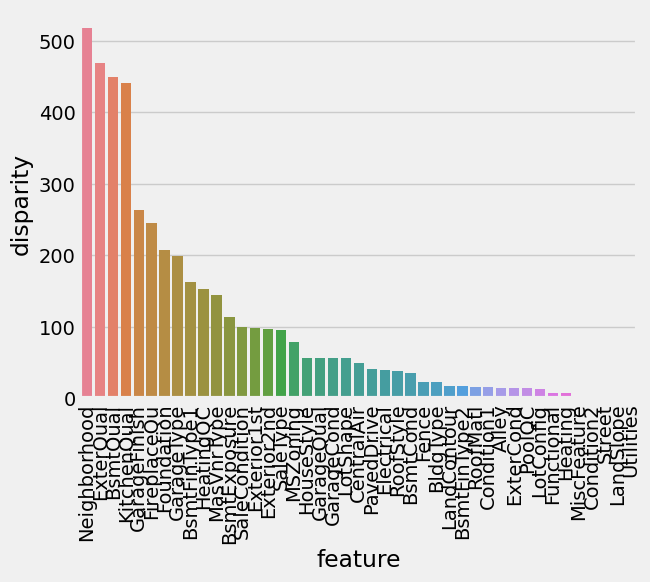

In [19]:
def anova(frame):
    anv = pd.DataFrame()
    anv['feature'] = qualitative
    pvals = []
    for c in qualitative:
        samples = []
        for cls in frame[c].unique():
            s = frame[frame[c] == cls]['SalePrice'].values
            samples.append(s)
        pval = stats.f_oneway(*samples)[1]
        pvals.append(pval)
    anv['pval'] = pvals
    return anv.sort_values('pval')

a = anova(train)
a['disparity'] = np.log(1./a['pval'].values)
sns.barplot(data=a, x='feature', y='disparity', hue = 'feature')
x=plt.xticks(rotation=90)

Here is quick estimation of influence of categorical variable on SalePrice. For each variable SalePrices are partitioned to distinct sets based on category values. Then check with ANOVA test if sets have similar distributions. If variable has minor impact then set means should be equal. Decreasing pval is sign of increasing diversity in partitions.

чем выше столбик, тем сильнее признак влияет на цену

Алгоритмы машинного обучения работают только с числами, поэтому все 43 категориальных признака нужно закодировать

In [20]:
def encode(frame, feature):
    ordering = pd.DataFrame()
    ordering['val'] = frame[feature].unique()
    ordering.index = ordering.val
    ordering['spmean'] = frame[[feature, 'SalePrice']].groupby(feature).mean()['SalePrice']
    ordering = ordering.sort_values('spmean')
    ordering['ordering'] = range(1, ordering.shape[0]+1)
    ordering = ordering['ordering'].to_dict()
    
    for cat, o in ordering.items():
        frame.loc[frame[feature] == cat, feature+'_E'] = o
    
qual_encoded = []
for q in qualitative:  
    encode(train, q)
    qual_encoded.append(q+'_E')
print(qual_encoded)

['MSZoning_E', 'Street_E', 'Alley_E', 'LotShape_E', 'LandContour_E', 'Utilities_E', 'LotConfig_E', 'LandSlope_E', 'Neighborhood_E', 'Condition1_E', 'Condition2_E', 'BldgType_E', 'HouseStyle_E', 'RoofStyle_E', 'RoofMatl_E', 'Exterior1st_E', 'Exterior2nd_E', 'MasVnrType_E', 'ExterQual_E', 'ExterCond_E', 'Foundation_E', 'BsmtQual_E', 'BsmtCond_E', 'BsmtExposure_E', 'BsmtFinType1_E', 'BsmtFinType2_E', 'Heating_E', 'HeatingQC_E', 'CentralAir_E', 'Electrical_E', 'KitchenQual_E', 'Functional_E', 'FireplaceQu_E', 'GarageType_E', 'GarageFinish_E', 'GarageQual_E', 'GarageCond_E', 'PavedDrive_E', 'PoolQC_E', 'Fence_E', 'MiscFeature_E', 'SaleType_E', 'SaleCondition_E']


Для каждой категории внутри признака вычисляется средняя цена дома (spmean). Затем категории сортируются от самой «дешёвой» к самой «дорогой» и получают порядковые номера 1, 2, 3....

Кодирование по возрастанию средней цены гарантирует монотонную связь: чем больше число в колонке feature_E, тем выше ожидаемая стоимость дома. Это помогает и линейным моделям, и деревьям решений находить закономерности гораздо быстрее.

В этом коде есть Data Leakage.

Когда вычисляется средняя цена SalePrice сразу по всей обучающей выборке, модель косвенно «подсматривает» ответы. Если в какой-то категории всего 1–2 дорогих дома, модель запомнит эту категорию как элитную и переобучится. Такое кодирование делают строго внутри кросс-валидации (например, через TargetEncoder или category_encoders).

## Correlations

Следует добавлять переменные которые не коррелируют друг с другом

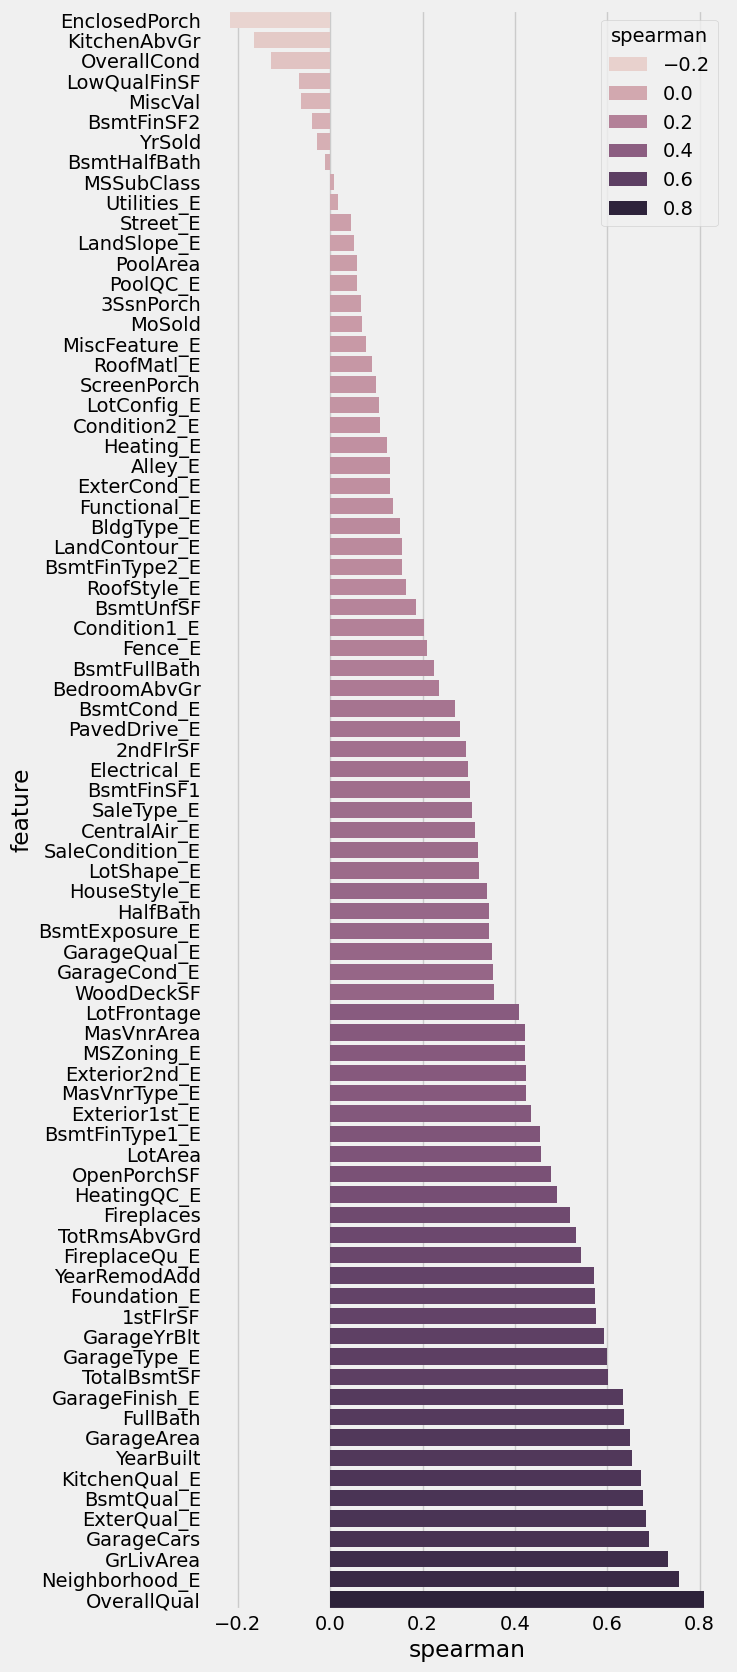

In [21]:
def spearman(frame, features):
    spr = pd.DataFrame()
    spr['feature'] = features
    spr['spearman'] = [frame[f].corr(frame['SalePrice'], 'spearman') for f in features]
    spr = spr.sort_values('spearman')
    plt.figure(figsize=(6, 0.25*len(features)))
    sns.barplot(data=spr, y='feature', x='spearman', orient='h', hue='spearman')
    
features = quantitative + qual_encoded
spearman(train, features)

Spearman correlation is better to work with in this case because it picks up relationships between variables even when they are nonlinear. OverallQual is main criterion in establishing house price. Neighborhood has big influence, partially it has some intrisinc value in itself, but also houses in certain regions tend to share same characteristics (confunding) what causes similar valuations.

<Axes: >

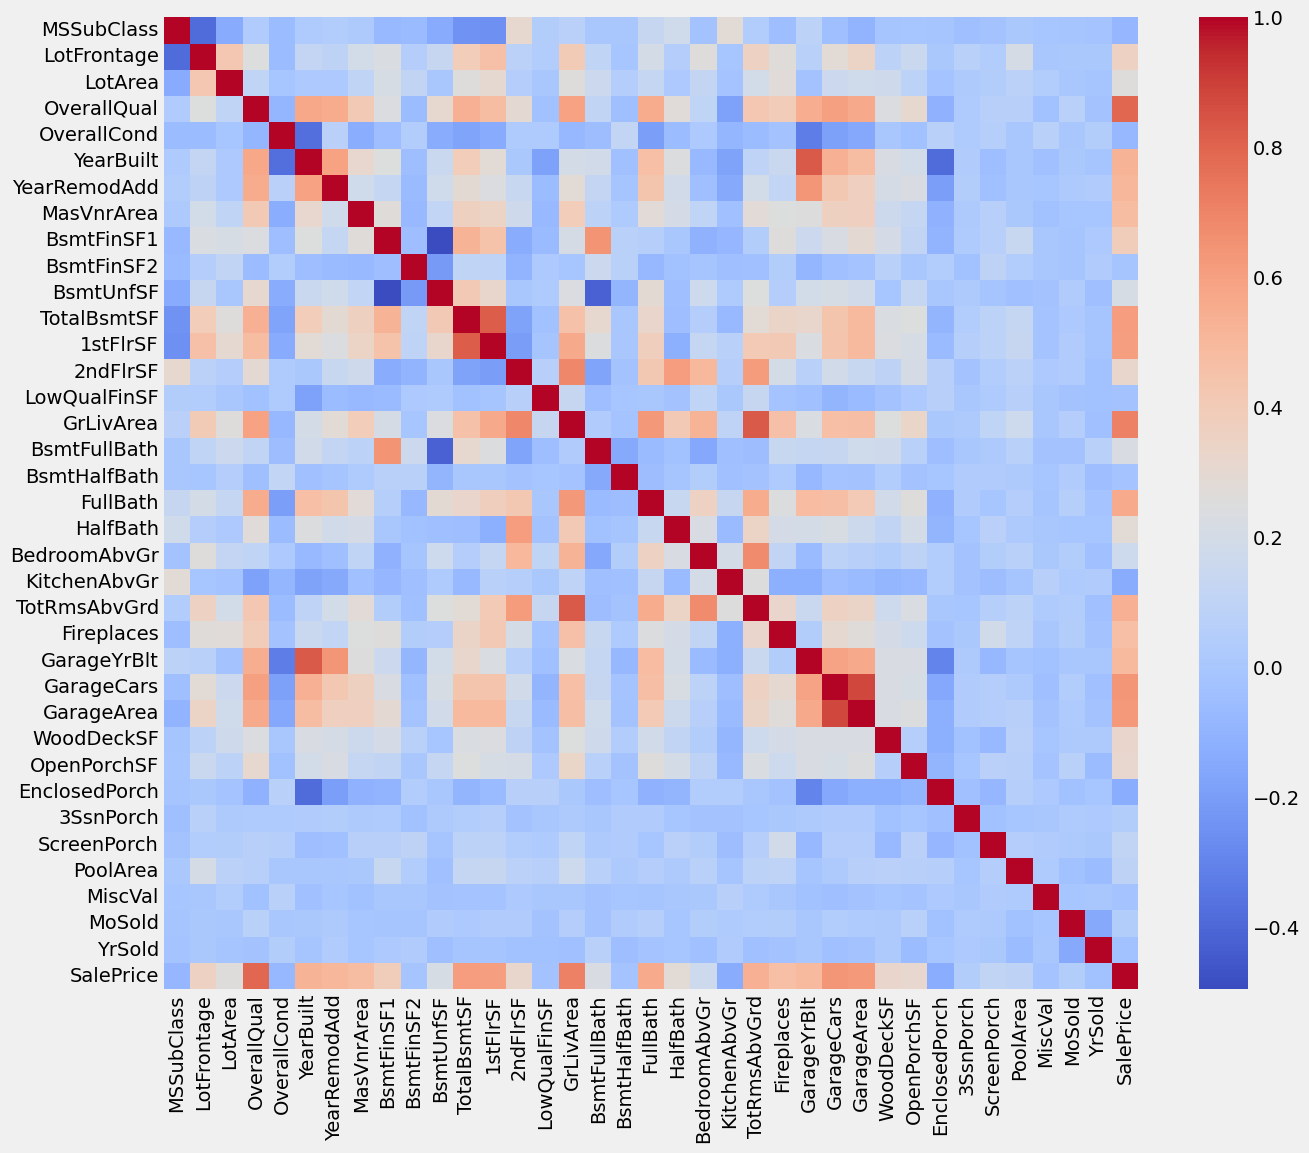

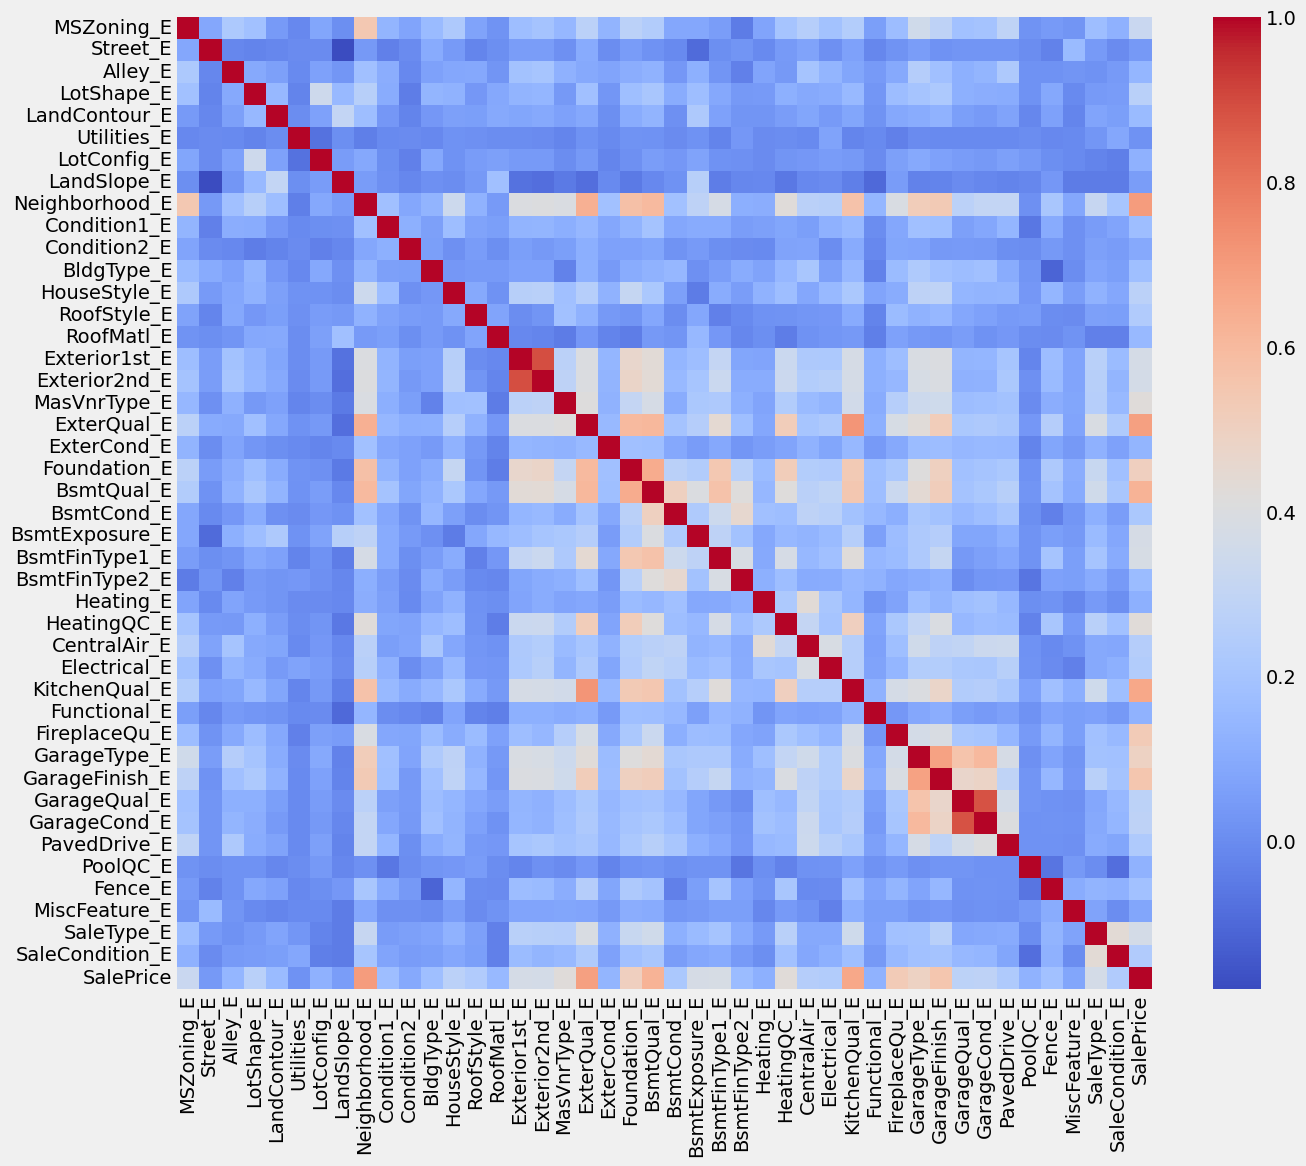

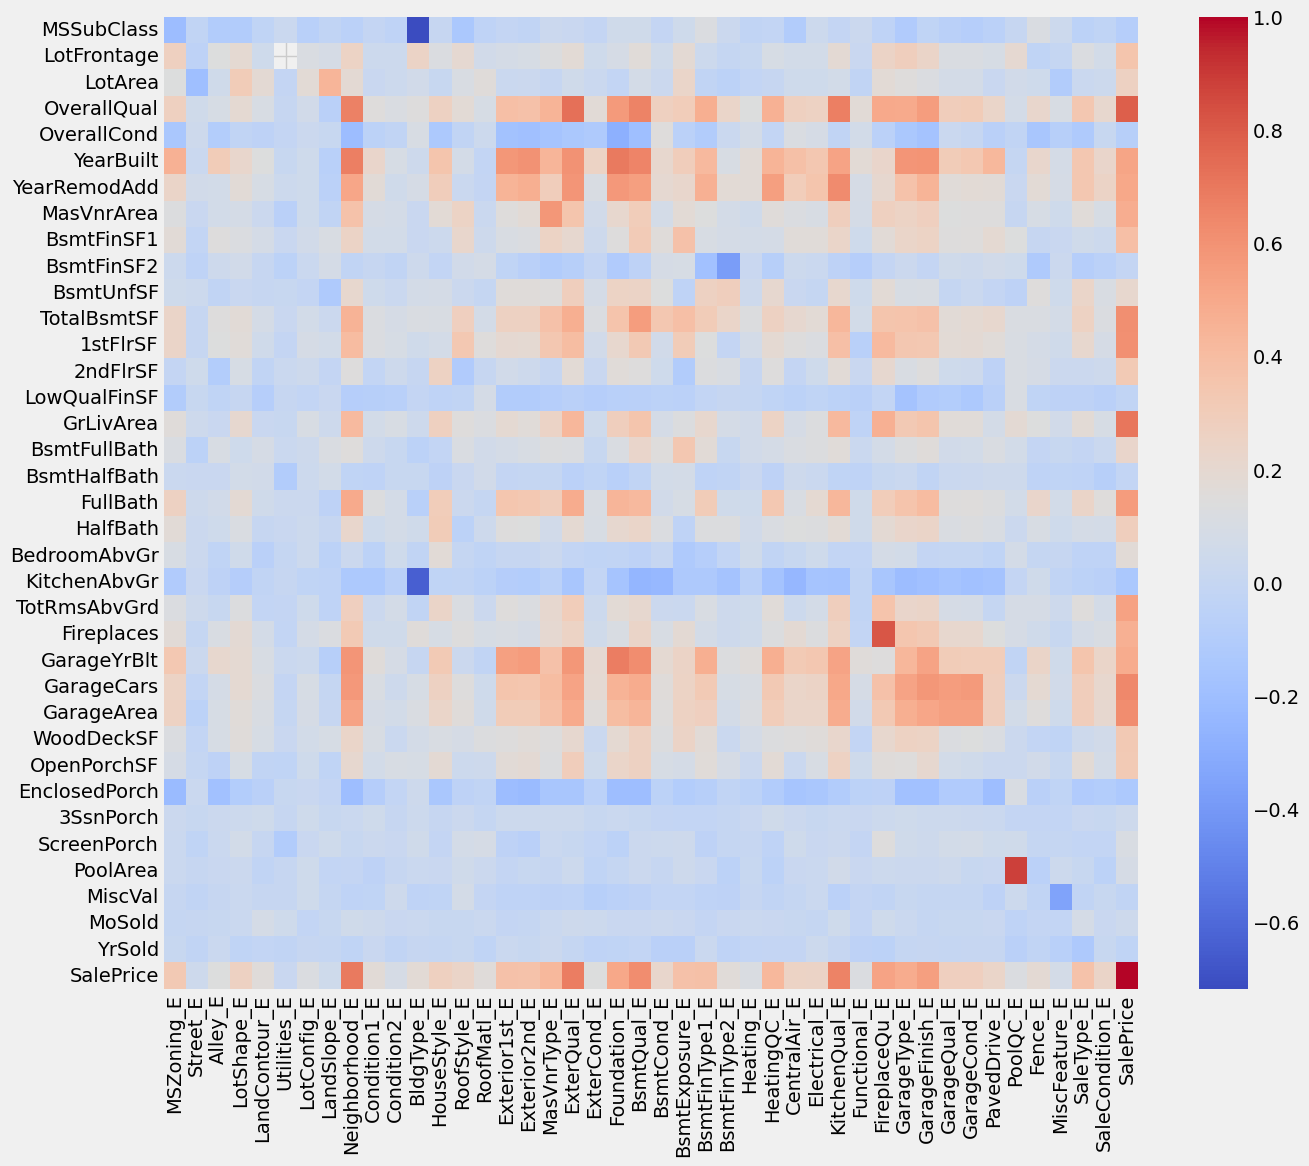

In [22]:
plt.figure(1, figsize=(14, 12))
corr = train[quantitative+['SalePrice']].corr()
sns.heatmap(corr,xticklabels=True , yticklabels=True,cmap='coolwarm')
plt.figure(2, figsize=(14, 12))
corr = train[qual_encoded+['SalePrice']].corr()
sns.heatmap(corr,xticklabels=True , yticklabels=True,cmap='coolwarm')
plt.figure(3, figsize=(14, 12))
corr = pd.DataFrame(np.zeros([len(quantitative)+1, len(qual_encoded)+1]), index=quantitative+['SalePrice'], columns=qual_encoded+['SalePrice'])
for q1 in quantitative+['SalePrice']:
    for q2 in qual_encoded+['SalePrice']:
        corr.loc[q1, q2] = train[q1].corr(train[q2])
sns.heatmap(corr,xticklabels=True , yticklabels=True,cmap='coolwarm')

There are many strong correlations between variables. Garages seem to be built same year as houses, basements have generally same area as first floor which is pretty obvious. Garage area is strongly correlated with number of cars. Neighborhood is correlated with lots of other variables and this confirms the idea that houses in same region share same characteristics. Dwelling type is negatively correlated with kitchen above grade square feet.

## Pairplots

It also would be useful to see how sale price compares to each independent variable.

KeyboardInterrupt: 



In [23]:
def pairplot(x, y, **kwargs):
    ax = plt.gca()
    ts = pd.DataFrame({'time': x, 'val': y})
    ts = ts.groupby('time').mean()
    ts.plot(ax=ax)
    plt.xticks(rotation=90)
    
f = pd.melt(train, id_vars=['SalePrice'], value_vars=quantitative+qual_encoded)
g = sns.FacetGrid(f, col="variable",  col_wrap=2, sharex=False, sharey=False, height=5)
g = g.map(pairplot, "value", "SalePrice")

There are lots of nonlinearities this may be the cause why some variables wont be selected by Lasso/Lars. Some factors like YearBuilt, 1stFlrSF, 2ndFlrSF, Neighborhood_E look like they would benefit from adding quadratic term to regression. But on the other hand this will most probably provoke overfit.

## Price Segments

It is possible that correlations shift with change of SalePrice.



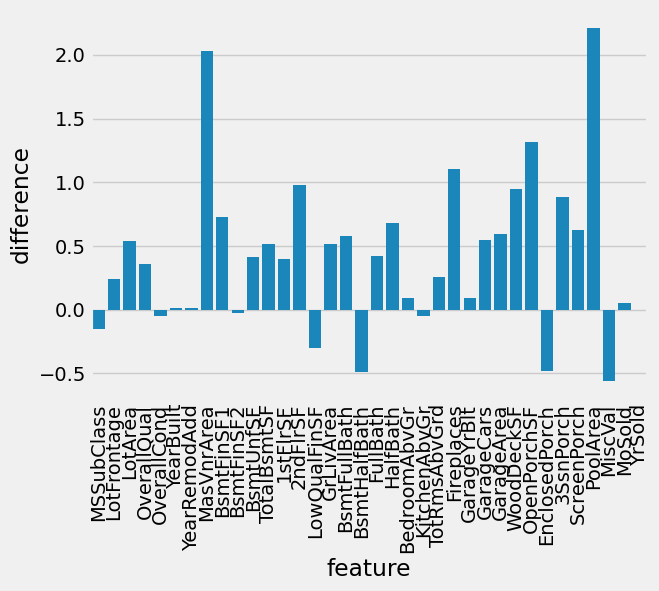

In [ ]:
features = quantitative

standard = train[train['SalePrice'] < 200000]
pricey = train[train['SalePrice'] >= 200000]

diff = pd.DataFrame()
diff['feature'] = features
diff['difference'] = [(pricey[f].fillna(0.).mean() - standard[f].fillna(0.).mean())/(standard[f].fillna(0.).mean())
                      for f in features]

sns.barplot(data=diff, x='feature', y='difference')
x=plt.xticks(rotation=90)

Here houses are divided in two price groups: cheap (under 200000) and expensive. Then means of quantitative variables are compared. Expensive houses have pools, better overall qual and condition, open porch and increased importance of MasVnrArea.

## Clustering

0.7516846874028444


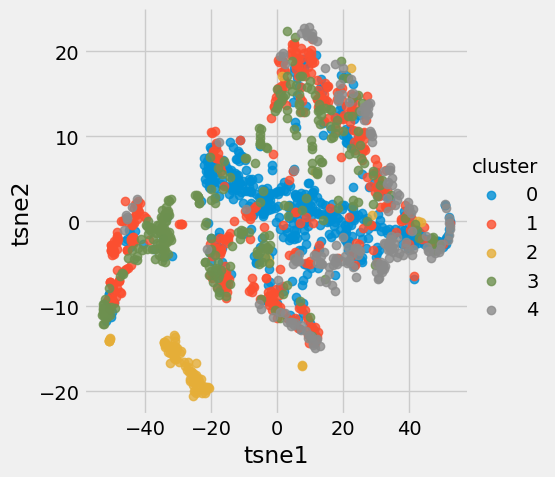

In [ ]:
features = quantitative + qual_encoded
model = TSNE(n_components=2, random_state=0, perplexity=50)
X = train[features].fillna(0.).values
tsne = model.fit_transform(X)

std = StandardScaler()
s = std.fit_transform(X)
pca = PCA(n_components=30)
pca.fit(s)
pc = pca.transform(s)
kmeans = KMeans(n_clusters=5)
kmeans.fit(pc)

fr = pd.DataFrame({'tsne1': tsne[:,0], 'tsne2': tsne[:, 1], 'cluster': kmeans.labels_})
sns.lmplot(data=fr, x='tsne1', y='tsne2', hue='cluster', fit_reg=False)
print(np.sum(pca.explained_variance_ratio_))

30 First PCA Components explain 75% of variance. There seems to be some clustering present but it is not enough for segmented regression.

<Axes: ylabel='Density'>

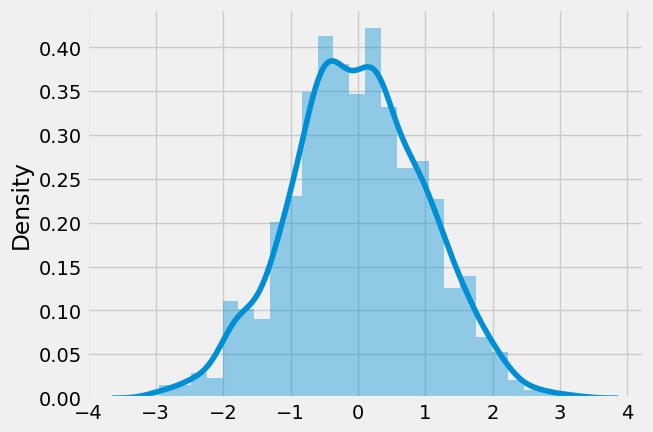

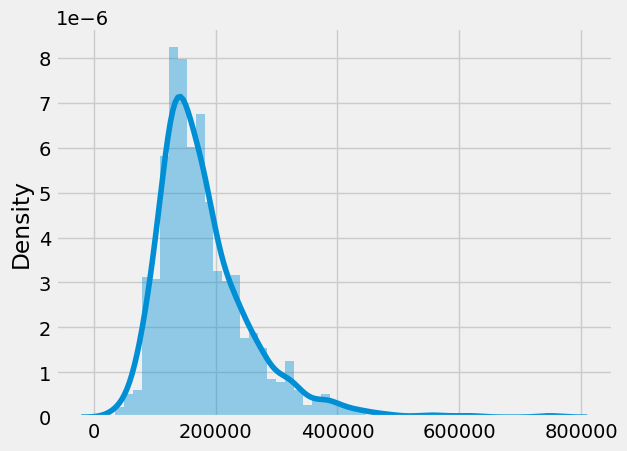

In [ ]:
y = train['SalePrice'].values
def johnson(y):
    gamma, eta, epsilon, lbda = stats.johnsonsu.fit(y)
    yt = gamma + eta*np.arcsinh((y-epsilon)/lbda)
    return yt, gamma, eta, epsilon, lbda

def johnson_inverse(y, gamma, eta, epsilon, lbda):
    return lbda*np.sinh((y-gamma)/eta) + epsilon

yt, g, et, ep, l = johnson(y)
yt2 = johnson_inverse(yt, g, et, ep, l)
plt.figure(1)
sns.distplot(yt)
plt.figure(2)
sns.distplot(yt2)

Here is Johnson Transform of SalePrice. I tried Box Cox, Fisher and Johnson transforms but none of these can beat log in simple linear regression. It is probably because they have tunable parameters that overfit to training data. If there were much more than 1500 instances they could be alternative to log transformation.

# Preproccessing

In [24]:
X = train.drop(columns=['Id', 'SalePrice'], errors='ignore')
y_log = np.log1p(train['SalePrice'])

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Ridge': Ridge(alpha=10.0),
    'Lasso': Lasso(),
    'SVR': SVR(C=1.0),
    'KNN': KNeighborsRegressor(n_neighbors=7),
    'DecisionTree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
    'CatBoost': CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
}

def evaluate_pipeline(preprocessor, X_data, y_data, experiment_name):
    """Возвращает среднюю ошибку RMSE по 5 фолдам для всех моделей."""
    results = {}
    for name, model in models.items():
        pipe = Pipeline([
            ('prep', preprocessor),
            ('model', model)
        ])
        scores = -cross_val_score(
            pipe, X_data, y_data, 
            scoring='neg_root_mean_squared_error', 
            cv=kf, n_jobs=-1
        )
        results[name] = np.mean(scores)
    return pd.Series(results, name=experiment_name)

In [25]:
history = pd.DataFrame()

## Обычная прогонка с нормализованными непрерывными и енкодед категориальными признаками

In [26]:
num_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_base = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=42))
])

prep_step0 = ColumnTransformer([
    ('num', num_base, num_cols),
    ('cat', cat_base, cat_cols)
])

In [27]:
history['0_Baseline'] = evaluate_pipeline(prep_step0, X, y_log, '0_Baseline')
print(history.round(4))

              0_Baseline
Ridge             0.1506
Lasso             0.3988
SVR               0.1359
KNN               0.1786
DecisionTree      0.2005
RandomForest      0.1448
XGBoost           0.1380
LightGBM          0.1323
CatBoost          0.1234


## Заполнение пропусков

In [28]:
def smart_imputation(df):
    df = df.copy()
    # Категории, где NaN = отсутствие объекта
    none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 
                 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
    for col in none_cols:
        if col in df.columns:
            df[col] = df[col].cat.add_categories(['None']).fillna('None')
            
    # Числа, где NaN = 0 (нет подвала/гаража -> площадь 0)
    zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'MasVnrArea',
                 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF']
    for col in zero_cols:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    return df

In [29]:
X_step1 = smart_imputation(X)
history['1_Smart_NaN'] = evaluate_pipeline(prep_step0, X_step1, y_log, '1_Smart_NaN')
print(history.round(4))

              0_Baseline  1_Smart_NaN
Ridge             0.1506       0.1507
Lasso             0.3988       0.3988
SVR               0.1359       0.1359
KNN               0.1786       0.1779
DecisionTree      0.2005       0.2011
RandomForest      0.1448       0.1448
XGBoost           0.1380       0.1371
LightGBM          0.1323       0.1322
CatBoost          0.1234       0.1234


## Логарифмирование скошенных признаков и бинарные флаги

In [30]:
def add_features_and_log(df):
    df = df.copy()
    # Бинарные флаги наличия
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasOpenPorch'] = (df['OpenPorchSF'] > 0).astype(int)
    
    # Объединение скоррелированных площадей
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    
    # Логарифмирование сильно скошенных числовых признаков (skew > 0.75)
    numeric_feats = df.select_dtypes(include=['int64', 'float64']).columns
    skewed_feats = df[numeric_feats].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
    high_skew = skewed_feats[abs(skewed_feats) > 0.75].index
    
    for feat in high_skew:
        # log1p безопасно обрабатывает нули
        if (df[feat] >= 0).all():
            df[feat] = np.log1p(df[feat])
            
    return df

In [31]:
X_step2 = add_features_and_log(X_step1)
# Обновляем список числовых колонок, так как появились новые фичи
num_cols_step2 = X_step2.select_dtypes(include=['int64', 'float64']).columns.tolist()

prep_step2 = ColumnTransformer([
    ('num', num_base, num_cols_step2),
    ('cat', cat_base, cat_cols)
])

In [32]:
history['2_Log_and_Feats'] = evaluate_pipeline(prep_step2, X_step2, y_log, '2_Log_and_Feats')
print(history.round(4))

              0_Baseline  1_Smart_NaN  2_Log_and_Feats
Ridge             0.1506       0.1507           0.1327
Lasso             0.3988       0.3988           0.3988
SVR               0.1359       0.1359           0.1301
KNN               0.1786       0.1779           0.1795
DecisionTree      0.2005       0.2011           0.2055
RandomForest      0.1448       0.1448           0.1428
XGBoost           0.1380       0.1371           0.1381
LightGBM          0.1323       0.1322           0.1309
CatBoost          0.1234       0.1234           0.1210


# GridSearch

### Первая прогонка

In [ ]:
models_dict = {
    'Ridge': Ridge(random_state=42),
    'Lasso': Lasso(random_state=42, max_iter=10000),
    'ElasticNet': ElasticNet(random_state=42, max_iter=10000),
    'SVR': SVR(),
    'KNN': KNeighborsRegressor(),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'RandomForest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(objective='reg:squarederror', eval_metric='rmse', tree_method='hist',random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(objective = 'regression',random_state=42, verbose=-1, n_jobs=-1),
    'CatBoost': CatBoostRegressor(
        bootstrap_type='Bernoulli',  # Обязательно для работы subsample
        random_state=42, 
        verbose=0, 
        thread_count=-1)
}

In [ ]:
# префикс 'model__' обязателен для Pipeline
#Первая прогонка
param_grids_dict = {
    'Ridge': {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'prep__cat__encoder__smooth': ['auto', 5.0, 15.0],
        'model__alpha': [0.5, 1.0, 5.0, 10.0, 20.0, 50.0],
        'model__positive': [False, True]
    },

    'Lasso': {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'prep__cat__encoder__smooth': ['auto', 5.0, 15.0],
        'model__alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01],
        'model__selection': ['cyclic', 'random'],
        'model__positive': [False, True]
    },

    'ElasticNet':{
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__alpha': [0.0005, 0.001, 0.005, 0.01, 0.05],
        'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
        'model__selection': ['cyclic', 'random']
    },

    'SVR': [{
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__kernel': ['rbf'],
        'model__C': [0.5, 1.0, 5.0, 10.0],
        'model__epsilon': [0.01, 0.05, 0.1],
        'model__gamma': ['scale', 0.001, 0.005, 0.01, 0.03]
    },
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__kernel': ['linear', 'poly'],
        'model__degree': [2],
        'model__C': [0.1, 1.0, 5.0],
        'model__epsilon': [0.01, 0.05, 0.1]
    }],

    'KNN': [
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
        'model__n_neighbors': [3, 5, 7, 11, 15, 21],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['minkowski'],
        'model__p': [1, 2]
    },
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__n_neighbors': [5, 7, 11, 15, 21],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['cosine']
    }
],
    'DecisionTree': {
        'model__max_depth': [4, 6, 8, 10],
        'model__min_samples_split': [2, 10, 20],
        'model__min_samples_leaf': [5, 10, 20],
        'model__max_features': [None, 0.5, 0.8],
        'model__ccp_alpha': [0.0, 0.0001, 0.0005, 0.001]
    },
    'RandomForest': {
        'model__n_estimators': [300, 500],
        'model__max_depth': [10, 15, None],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 3, 5],
        'model__max_features': ['sqrt', 0.4, 0.6],
        'model__max_samples': [0.75, 0.9, None],
        'model__ccp_alpha': [0.0, 0.0001]
    },
    'XGBoost': {
        'model__iterations': [3000],
        'model__early_stopping_rounds': [50],
        'model__learning_rate': [0.02, 0.05],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8],
        'model__colsample_bytree': [0.8]
    },
    'LightGBM': {
        'model__iterations': [3000],
        'model__early_stopping_rounds': [50],
        'model__learning_rate': [0.02, 0.05],
        'model__num_leaves': [15, 31],
        'model__min_child_samples': [10, 20],
        'model__subsample': [0.8],
        'model__extra_trees': [False, True],
        'model__reg_alpha': [0.0, 0.1, 1.0],
        'model__reg_lambda': [0.1, 1.0, 5.0]
    },
    'CatBoost': {
        'model__iterations': [3000],
        'model__early_stopping_rounds': [50],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__depth': [3, 5, 7],
        'model__l2_leaf_reg': [1, 3, 5, 7],
        'model__subsample': [0.75, 0.9],  # Доля строк
        'model__rsm': [0.7, 0.9]          # Доля признаков
    }
}

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

best_summary = []      # Для лучших параметров каждой модели
all_cv_details = []    # Для всех проверенных комбинаций
best_estimators = {}   # Сохраняем обученные лучшие пайплайны в память

# Используем лучший препроцессор и данные из предыдущего шага
current_prep = prep_step2
current_X = X_step2

for name, model in models_dict.items():
    print(f"Идет поиск для {name}...")
    start_time = time.time()
    
    pipe = Pipeline([
        ('prep', current_prep),
        ('model', model)
    ])
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids_dict[name],
        scoring='neg_root_mean_squared_error',
        cv=kf,
        n_jobs=-1,
        return_train_score=True
    )
    
    grid.fit(current_X, y_log)
    elapsed = round(time.time() - start_time, 2)
    best_rmse = -grid.best_score_
    
    # Сохраняем лучший пайплайн
    best_estimators[name] = grid.best_estimator_
    
    # 1. Записываем краткую сводку по модели
    best_summary.append({
        'Model': name,
        'Best_CV_RMSE': round(best_rmse, 5),
        'Time_sec': elapsed,
        'Best_Params': str(grid.best_params_)
    })
    
    # 2. Записываем детальную статистику всех комбинаций сетки
    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df['Model'] = name
    cv_df['Mean_Val_RMSE'] = -cv_df['mean_test_score']
    cv_df['Mean_Train_RMSE'] = -cv_df['mean_train_score']
    all_cv_details.append(cv_df[['Model', 'Mean_Val_RMSE', 'Mean_Train_RMSE', 'std_test_score', 'params']])
    
    # Промежуточное сохранение после каждой модели
    pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').to_csv('gridsearch_summary.csv', index=False)
    pd.concat(all_cv_details, ignore_index=True).to_csv('gridsearch_all_combinations.csv', index=False)
    
    print(f"  Готово за {elapsed} сек. Лучший RMSE: {best_rmse:.5f}")

# Выводим итоговый лидерборд
summary_df = pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').reset_index(drop=True)
print("\nИтоговая таблица лидеров:")
print(summary_df)

Идет поиск для Ridge...
  Готово за 24.75 сек. Лучший RMSE: 0.12872
Идет поиск для Lasso...
  Готово за 22.95 сек. Лучший RMSE: 0.12923
Идет поиск для ElasticNet...
  Готово за 16.37 сек. Лучший RMSE: 0.12923
Идет поиск для SVR...
  Готово за 143.63 сек. Лучший RMSE: 0.12544
Идет поиск для KNN...
  Готово за 15.79 сек. Лучший RMSE: 0.16463
Идет поиск для DecisionTree...
  Готово за 37.43 сек. Лучший RMSE: 0.17942
Идет поиск для RandomForest...
  Готово за 1671.04 сек. Лучший RMSE: 0.13599
Идет поиск для XGBoost...


ValueError: 
All the 30 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "d:\miniconda\envs\titanic-ml\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "d:\miniconda\envs\titanic-ml\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "d:\miniconda\envs\titanic-ml\lib\site-packages\sklearn\pipeline.py", line 663, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "d:\miniconda\envs\titanic-ml\lib\site-packages\xgboost\core.py", line 751, in inner_f
    return func(**kwargs)
  File "d:\miniconda\envs\titanic-ml\lib\site-pack

Передали параметр early_stopping_rounds в XGBRegressor. Ранняя остановка требует, чтобы в метод .fit() передавался валидационный набор eval_set=[(X_val, y_val)]. Но внутри GridSearchCV и Pipeline метод .fit() вызывается без eval_set — кросс-валидация сама проверяет качество уже после обучения модели.

### Вторая прогонка

In [ ]:
param_grids_dict = {
    'Ridge': {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'prep__cat__encoder__smooth': ['auto', 5.0, 15.0],
        'model__alpha': [0.5, 1.0, 5.0, 10.0, 20.0, 50.0],
        'model__positive': [False, True]
    },

    'Lasso': {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'prep__cat__encoder__smooth': ['auto', 5.0, 15.0],
        'model__alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01],
        'model__selection': ['cyclic', 'random'],
        'model__positive': [False, True]
    },

    'ElasticNet':{
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__alpha': [0.0005, 0.001, 0.005, 0.01, 0.05],
        'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
        'model__selection': ['cyclic', 'random']
    },

    'SVR': [{
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__kernel': ['rbf'],
        'model__C': [0.5, 1.0, 5.0, 10.0],
        'model__epsilon': [0.01, 0.05, 0.1],
        'model__gamma': ['scale', 0.001, 0.005, 0.01, 0.03]
    },
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__kernel': ['linear', 'poly'],
        'model__degree': [2],
        'model__C': [0.1, 1.0, 5.0],
        'model__epsilon': [0.01, 0.05, 0.1]
    }],

    'KNN': [
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
        'model__n_neighbors': [3, 5, 7, 11, 15, 21],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['minkowski'],
        'model__p': [1, 2]
    },
    {
        'prep__num__scaler': [StandardScaler(), RobustScaler()],
        'model__n_neighbors': [5, 7, 11, 15, 21],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['cosine']
    }
],
    'DecisionTree': {
        'model__max_depth': [4, 6, 8, 10],
        'model__min_samples_split': [2, 10, 20],
        'model__min_samples_leaf': [5, 10, 20],
        'model__max_features': [None, 0.5, 0.8],
        'model__ccp_alpha': [0.0, 0.0001, 0.0005, 0.001]
    },
    'RandomForest': {
        'model__n_estimators': [300, 500],
        'model__max_depth': [10, 15, None],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 3, 5],
        'model__max_features': ['sqrt', 0.4, 0.6],
        'model__max_samples': [0.75, 0.9, None],
        'model__ccp_alpha': [0.0, 0.0001]
    },
    'XGBoost': {
        'model__iterations': [300, 600, 1000],
        'model__learning_rate': [0.02, 0.05],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8],
        'model__colsample_bytree': [0.8]
    },
    'LightGBM': {
        'model__iterations': [300, 600, 1000],
        'model__learning_rate': [0.02, 0.05],
        'model__num_leaves': [15, 31],
        'model__min_child_samples': [10, 20],
        'model__subsample': [0.8],
        'model__extra_trees': [False, True],
        'model__reg_alpha': [0.0, 0.1, 1.0],
        'model__reg_lambda': [0.1, 1.0, 5.0]
    },
    'CatBoost': {
        'model__iterations': [300, 600, 1000],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__depth': [3, 5, 7],
        'model__l2_leaf_reg': [1, 3, 5, 7],
        'model__subsample': [0.75, 0.9],  # Доля строк
        'model__rsm': [0.7, 0.9]          # Доля признаков
    }
}

In [ ]:
for name, model in models_dict.items():
    if name in best_estimators:
        print(f"Модель {name} уже обучена, пропускаем...")
        continue
        
    print(f"Идет поиск для {name}...")
    start_time = time.time()
    
    pipe = Pipeline([
        ('prep', current_prep),
        ('model', model)
    ])
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids_dict[name],
        scoring='neg_root_mean_squared_error',
        cv=kf,
        n_jobs=-1,
        return_train_score=True
    )
    
    grid.fit(current_X, y_log)
    elapsed = round(time.time() - start_time, 2)
    best_rmse = -grid.best_score_
    
    # Дописываем в существующие структуры
    best_estimators[name] = grid.best_estimator_
    
    best_summary.append({
        'Model': name,
        'Best_CV_RMSE': round(best_rmse, 5),
        'Time_sec': elapsed,
        'Best_Params': str(grid.best_params_)
    })
    
    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df['Model'] = name
    cv_df['Mean_Val_RMSE'] = -cv_df['mean_test_score']
    cv_df['Mean_Train_RMSE'] = -cv_df['mean_train_score']
    all_cv_details.append(cv_df[['Model', 'Mean_Val_RMSE', 'Mean_Train_RMSE', 'std_test_score', 'params']])
    
    # Обновляем CSV-файлы
    pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').to_csv('gridsearch_summary.csv', index=False)
    pd.concat(all_cv_details, ignore_index=True).to_csv('gridsearch_all_combinations.csv', index=False)
    
    print(f"  Готово за {elapsed} сек. Лучший RMSE: {best_rmse:.5f}")

# Выводим итоговую таблицу
summary_df = pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').reset_index(drop=True)
print("\nИтоговая таблица лидеров:")
print(summary_df)

Модель Ridge уже обучена, пропускаем...
Модель Lasso уже обучена, пропускаем...
Модель ElasticNet уже обучена, пропускаем...
Модель SVR уже обучена, пропускаем...
Модель KNN уже обучена, пропускаем...
Модель DecisionTree уже обучена, пропускаем...
Модель RandomForest уже обучена, пропускаем...
Идет поиск для XGBoost...
  Готово за 42.14 сек. Лучший RMSE: 0.13041
Идет поиск для LightGBM...
  Готово за 249.96 сек. Лучший RMSE: 0.12657
Идет поиск для CatBoost...
  Готово за 2368.2 сек. Лучший RMSE: 0.12035

Итоговая таблица лидеров:
          Model  Best_CV_RMSE  Time_sec  \
0      CatBoost       0.12035   2368.20   
1           SVR       0.12544    143.63   
2      LightGBM       0.12657    249.96   
3         Ridge       0.12872     24.75   
4         Lasso       0.12923     22.95   
5    ElasticNet       0.12923     16.37   
6       XGBoost       0.13041     42.14   
7  RandomForest       0.13599   1671.04   
8           KNN       0.16463     15.79   
9  DecisionTree       0.17942     

У CatBoost оптимум пришелся на iterations=1000 при learning_rate=0.05. Вероятно, модель не до конца сошлась — стоит проверить 1200–1600 итераций с более плавным шагом (0.025–0.04).

У LightGBM и XGBoost лучший результат получился на iterations=300 и learning_rate=0.05. Увеличим деревья до 500–700 при снижении learning_rate до 0.02–0.03

В Ridge и Lasso сглаживание категориального энкодера prep__cat__encoder__smooth=5.0 стоит расширить в обе стороны (2.0, 5.0, 10.0, 15.0), а скейлер RobustScaler() можно зафиксировать, чтобы не тратить время на перебор.

В ElasticNet лучший l1_ratio=0.1 тяготеет к L2-регуляризации (Ridge сработал лучше), поэтому имеет смысл проверить значения 0.02 и 0.05.

Уберем RandomForest (долго обучается, слабее даже линейных моделей), KNN (неподходящий алгоритм для этой задачи), DecisionTree (сильно уступает ансамблям)

Прогоним третий раз, чтобы найти в окрестности лучших еще лучше

### Третья прогонка

In [33]:
models_dict = {
    'Ridge': Ridge(random_state=42),
    'Lasso': Lasso(random_state=42, max_iter=10000),
    'ElasticNet': ElasticNet(random_state=42, max_iter=10000),
    'SVR': SVR(),
    'XGBoost': XGBRegressor(objective='reg:squarederror', eval_metric='rmse', tree_method='hist',random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(objective = 'regression',random_state=42, verbose=-1, n_jobs=-1),
    'CatBoost': CatBoostRegressor(
        bootstrap_type='Bernoulli',  # Обязательно для работы subsample
        random_state=42, 
        verbose=0, 
        thread_count=-1)
}

In [ ]:
refined_param_grids = {
    "CatBoost": {
        "model__depth": [4, 5, 6],
        "model__iterations": [1000, 1300, 1600],
        "model__learning_rate": [0.025, 0.035, 0.05],
        "model__l2_leaf_reg": [2, 3, 5, 7],
        "model__rsm": [0.85, 0.9, 0.95],
        "model__subsample": [0.85, 0.9, 0.95],
    },
    "SVR": {
        "model__C": [2.5, 4.0, 5.0, 6.5, 8.0],
        "model__epsilon": [0.005, 0.01, 0.015, 0.02],
        "model__gamma": ["scale", 0.01, 0.02, 0.05],
        "model__kernel": ["rbf"],
        "prep__num__scaler": [StandardScaler()],
    },
    "LightGBM": {
        "model__extra_trees": [True],
        "model__iterations": [300, 500, 700],
        "model__learning_rate": [0.02, 0.03, 0.05],
        "model__num_leaves": [23, 31, 40],
        "model__min_child_samples": [7, 10, 15, 20],
        "model__reg_alpha": [0.05, 0.1, 0.25],
        "model__reg_lambda": [0.5, 1.0, 2.0],
        "model__subsample": [0.75, 0.8, 0.85],
    },
    "Ridge": {
        "model__alpha": [2.0, 3.5, 5.0, 6.5, 8.0, 10.0],
        "model__positive": [True],
        "prep__cat__encoder__smooth": [2.0, 5.0, 10.0, 15.0],
        "prep__num__scaler": [RobustScaler()],
    },
    "Lasso": {
        "model__alpha": [0.0002, 0.00035, 0.0005, 0.0007, 0.001],
        "model__positive": [True],
        "model__selection": ["random"],
        "prep__cat__encoder__smooth": [2.0, 5.0, 10.0, 15.0],
        "prep__num__scaler": [RobustScaler()],
    },
    "ElasticNet": {
        "model__alpha": [0.02, 0.035, 0.05, 0.07, 0.1],
        "model__l1_ratio": [0.02, 0.05, 0.1, 0.15, 0.2],
        "model__selection": ["cyclic"],
        "prep__num__scaler": [StandardScaler()],
    },
    "XGBoost": {
        "model__iterations": [300, 500, 700],
        "model__learning_rate": [0.02, 0.03, 0.05],
        "model__max_depth": [4, 5, 6],
        "model__colsample_bytree": [0.7, 0.8, 0.9],
        "model__subsample": [0.7, 0.8, 0.9],
        "model__reg_alpha": [0.0, 0.1, 0.5],
        "model__reg_lambda": [1.0, 2.0, 5.0],
    },
}

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

best_summary = []      # Для лучших параметров каждой модели
all_cv_details = []    # Для всех проверенных комбинаций
best_estimators = {}   # Сохраняем обученные лучшие пайплайны в память

# Используем лучший препроцессор и данные из предыдущего шага
current_prep = prep_step2
current_X = X_step2

for name, model in models_dict.items():
    print(f"Идет поиск для {name}...")
    start_time = time.time()
    
    pipe = Pipeline([
        ('prep', current_prep),
        ('model', model)
    ])
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=refined_param_grids[name],
        scoring='neg_root_mean_squared_error',
        cv=kf,
        n_jobs=-1,
        return_train_score=True
    )
    
    grid.fit(current_X, y_log)
    elapsed = round(time.time() - start_time, 2)
    best_rmse = -grid.best_score_
    
    # Сохраняем лучший пайплайн
    best_estimators[name] = grid.best_estimator_
    
    # 1. Записываем краткую сводку по модели
    best_summary.append({
        'Model': name,
        'Best_CV_RMSE': round(best_rmse, 5),
        'Time_sec': elapsed,
        'Best_Params': str(grid.best_params_)
    })
    
    # 2. Записываем статистику всех комбинаций сетки
    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df['Model'] = name
    cv_df['Mean_Val_RMSE'] = -cv_df['mean_test_score']
    cv_df['Mean_Train_RMSE'] = -cv_df['mean_train_score']
    all_cv_details.append(cv_df[['Model', 'Mean_Val_RMSE', 'Mean_Train_RMSE', 'std_test_score', 'params']])
    
    # Промежуточное сохранение после каждой модели
    pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').to_csv('gridsearch_summary_correction.csv', index=False)
    pd.concat(all_cv_details, ignore_index=True).to_csv('gridsearch_all_combinations_correction.csv', index=False)
    
    print(f"  Готово за {elapsed} сек. Лучший RMSE: {best_rmse:.5f}")

# Выводим итоговый лидерборд
summary_df = pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').reset_index(drop=True)
print("\nИтоговая таблица лидеров:")
print(summary_df) 

Прерывание, дообучаем кэтбуст

In [34]:
models_dict = {
    'CatBoost': CatBoostRegressor(
        bootstrap_type='Bernoulli',  # Обязательно для работы subsample
        random_state=42, 
        verbose=0, 
        thread_count=-1)
}

In [35]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

best_summary = []      # Для лучших параметров каждой модели
all_cv_details = []    # Для всех проверенных комбинаций
best_estimators = {}   # Сохраняем обученные лучшие пайплайны в память

# Используем лучший препроцессор и данные из предыдущего шага
current_prep = prep_step2
current_X = X_step2

for name, model in models_dict.items():
    print(f"Идет поиск для {name}...")
    start_time = time.time()
    
    pipe = Pipeline([
        ('prep', current_prep),
        ('model', model)
    ])
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=refined_param_grids[name],
        scoring='neg_root_mean_squared_error',
        cv=kf,
        n_jobs=-1,
        return_train_score=True
    )
    
    grid.fit(current_X, y_log)
    elapsed = round(time.time() - start_time, 2)
    best_rmse = -grid.best_score_
    
    # Сохраняем лучший пайплайн
    best_estimators[name] = grid.best_estimator_
    
    # 1. Записываем краткую сводку по модели
    best_summary.append({
        'Model': name,
        'Best_CV_RMSE': round(best_rmse, 5),
        'Time_sec': elapsed,
        'Best_Params': str(grid.best_params_)
    })
    
    # 2. Записываем статистику всех комбинаций сетки
    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df['Model'] = name
    cv_df['Mean_Val_RMSE'] = -cv_df['mean_test_score']
    cv_df['Mean_Train_RMSE'] = -cv_df['mean_train_score']
    all_cv_details.append(cv_df[['Model', 'Mean_Val_RMSE', 'Mean_Train_RMSE', 'std_test_score', 'params']])
    
    # Промежуточное сохранение после каждой модели
    pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').to_csv('gridsearch_summary_correction_catboost.csv', index=False)
    pd.concat(all_cv_details, ignore_index=True).to_csv('gridsearch_all_combinations_correction_catboost.csv', index=False)
    
    print(f"  Готово за {elapsed} сек. Лучший RMSE: {best_rmse:.5f}")

# Выводим итоговый лидерборд
summary_df = pd.DataFrame(best_summary).sort_values('Best_CV_RMSE').reset_index(drop=True)
print("\nИтоговая таблица лидеров:")
print(summary_df)

Идет поиск для CatBoost...
  Готово за 8944.05 сек. Лучший RMSE: 0.11928

Итоговая таблица лидеров:
      Model  Best_CV_RMSE  Time_sec  \
0  CatBoost       0.11928   8944.05   

                                         Best_Params  
0  {'model__depth': 5, 'model__iterations': 1600,...  


# DNN

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision.transforms import v2

from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader, random_split

import os
import json
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

from PIL import Image
from tqdm import tqdm

from typing import List, Tuple, Type, Optional
from itertools import product
from copy import deepcopy

import random

## Cleaning function and Creating dataset